<a href="https://colab.research.google.com/github/20deepak28/Customer-Lifetime-Value-Churn-Intelligence/blob/main/08_customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 08 — Customer Segmentation Using K-Means
### Objective: Identify distinct customer groups using unsupervised machine learning and develop actionable business strategies for each segment.

We'll use K-Means clustering on customer-level purchasing behaviour.
Notebook roadmap
1. Import libraries and load datasets.
2. Prepare customer-level features.
3. Perform feature scaling.
4. Find optimal clusters using the Elbow Method.
5. Evaluate clusters using Silhouette Score.
6. Apply K-Means clustering.
7. Visualise customer segments.
8. Profile and interpret each cluster.
9. Develop business recommendations.
10. Save the segmented customer dataset.

In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Project directory
PROJECT_PATH = "/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence"

DATA_PATH = os.path.join(PROJECT_PATH, "data")
MODEL_PATH = os.path.join(PROJECT_PATH, "models")
NOTEBOOK_PATH = os.path.join(PROJECT_PATH, "notebooks")

# Create required folders if missing
os.makedirs(MODEL_PATH, exist_ok=True)

# List available datasets
print("Available datasets:")
for file in os.listdir(DATA_PATH):
    print(file)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Available datasets:
telco_churn_raw.csv
telco_churn_processed.csv
telco_churn_feature_engineered.csv


In [4]:
import os
import urllib.request

DATA_PATH = "/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence/data"

os.makedirs(DATA_PATH, exist_ok=True)

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx"

file_path = os.path.join(DATA_PATH, "online_retail_II.xlsx")

if not os.path.exists(file_path):
    print("Downloading Online Retail II dataset...")
    urllib.request.urlretrieve(url, file_path)

print("Download completed!")
print("File size:", round(os.path.getsize(file_path) / (1024**2), 2), "MB")
print("Saved at:", file_path)

Download completed!
File size: 43.51 MB
Saved at: /content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence/data/online_retail_II.xlsx


### Load and prepare customer Data

In [5]:
# Load cleaned transaction data
file_path = os.path.join(DATA_PATH, "online_retail_II.xlsx")

df_2009 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
df_2010 = pd.read_excel(file_path, sheet_name="Year 2010-2011")

retail_df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print("Original dataset shape:", retail_df.shape)

# Standardise column names
retail_df.columns = retail_df.columns.str.strip()

# Remove duplicate transactions
retail_df = retail_df.drop_duplicates()

# Remove missing customer IDs
retail_df = retail_df.dropna(subset=["Customer ID"])

# Exclude cancelled invoices
retail_df = retail_df[
    ~retail_df["Invoice"].astype(str).str.startswith("C")
]

# Keep positive quantities and prices
retail_df = retail_df[
    (retail_df["Quantity"] > 0) &
    (retail_df["Price"] > 0)
].copy()

# Calculate revenue
retail_df["Revenue"] = (
    retail_df["Quantity"] * retail_df["Price"]
)

print("\nCleaned dataset shape:", retail_df.shape)
print("Unique customers:", retail_df["Customer ID"].nunique())
print("Missing values:", retail_df.isnull().sum().sum())
print("Duplicate rows:", retail_df.duplicated().sum())

Original dataset shape: (1067371, 8)

Cleaned dataset shape: (779425, 9)
Unique customers: 5878
Missing values: 0
Duplicate rows: 0


### Customer Level Feature engineering

In [6]:
# Reference date for recency
reference_date = retail_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Customer-level aggregation
customer_features = retail_df.groupby("Customer ID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    TotalInvoices=("Invoice", "nunique")
).reset_index()

# Calculate additional features
customer_features["Recency"] = (
    reference_date - customer_features["LastPurchase"]
).dt.days

customer_features["CustomerTenure"] = (
    customer_features["LastPurchase"] -
    customer_features["FirstPurchase"]
).dt.days

customer_features["AverageOrderValue"] = (
    customer_features["Monetary"] /
    customer_features["Frequency"]
)

customer_features["AverageQuantity"] = (
    customer_features["TotalQuantity"] /
    customer_features["Frequency"]
)

# Remove date columns from clustering features
customer_features.drop(
    columns=["FirstPurchase", "LastPurchase"],
    inplace=True
)

print("Customer-level dataset shape:", customer_features.shape)
display(customer_features.head(10))

Customer-level dataset shape: (5878, 9)


,Customer ID,Frequency,Monetary,TotalQuantity,TotalInvoices,Recency,CustomerTenure,AverageOrderValue,AverageQuantity
0,12346.0,12,77556.46,74285,12,326,400,6463.038333,6190.416667
1,12347.0,8,4921.53,2967,8,2,402,615.191250,370.875000
2,12348.0,5,2019.40,2714,5,75,362,403.880000,542.800000
3,12349.0,4,4428.69,1624,4,19,570,1107.172500,406.000000
4,12350.0,1,334.40,197,1,310,0,334.400000,197.000000
5,12351.0,1,300.93,261,1,375,0,300.930000,261.000000
6,12352.0,10,2849.84,724,10,36,356,284.984000,72.400000
7,12353.0,2,406.76,212,2,204,204,203.380000,106.000000
8,12354.0,1,1079.40,530,1,232,0,1079.400000,530.000000
9,12355.0,2,947.61,543,2,214,353,473.805000,271.500000


### Distribution and outliers analysis

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Recency,5878.0,201.331916,209.338707,1.00,26.0000,96.000000,380.000000,535.000000,625.000000,726.000000,739.00
Frequency,5878.0,6.289384,13.009406,1.00,1.0000,3.000000,7.000000,13.000000,21.000000,46.000000,398.00
Monetary,5878.0,2955.904095,14440.852688,2.95,342.2800,867.740000,2248.305000,5465.741000,9374.227000,29205.901000,580987.04
CustomerTenure,5878.0,273.022457,258.807591,0.00,0.0000,220.500000,511.000000,667.000000,712.000000,732.000000,738.00
AverageOrderValue,5878.0,385.180841,1214.286459,2.95,176.6825,279.242679,414.902458,631.523667,891.164500,1963.810500,84236.25
AverageQuantity,5878.0,247.556853,1424.480958,1.00,91.0000,153.583333,256.926136,398.713636,545.246964,1285.220909,87167.00



Feature Skewness:


,Skewness
AverageOrderValue,57.132568
AverageQuantity,47.907131
Monetary,25.070190
Frequency,12.639951
Recency,0.887198
CustomerTenure,0.388825


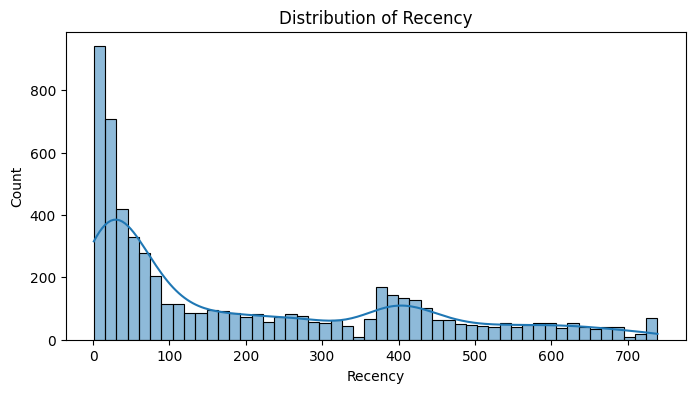

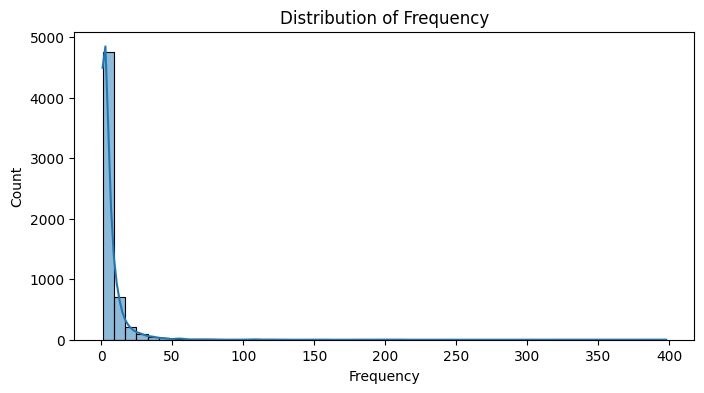

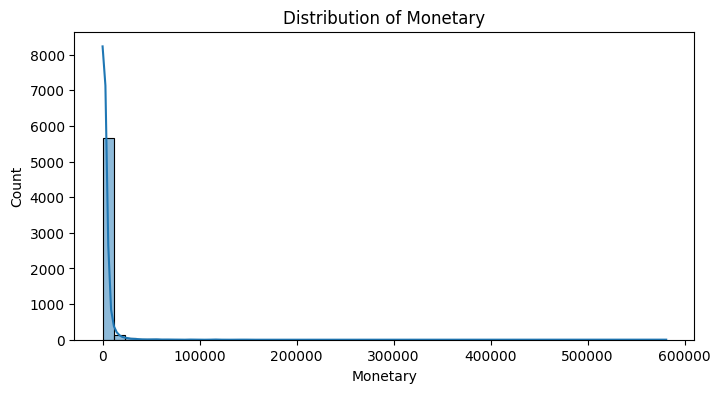

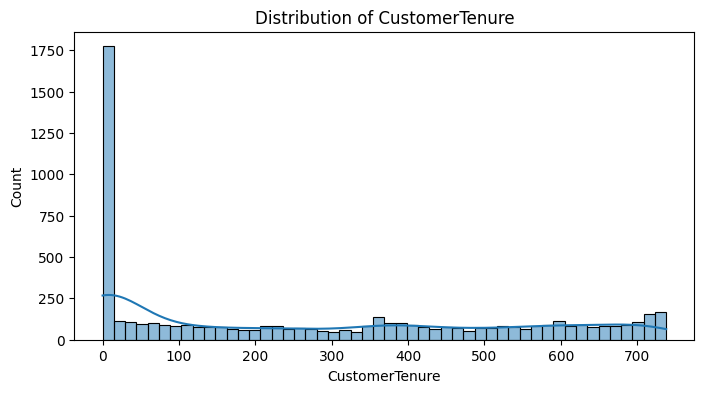

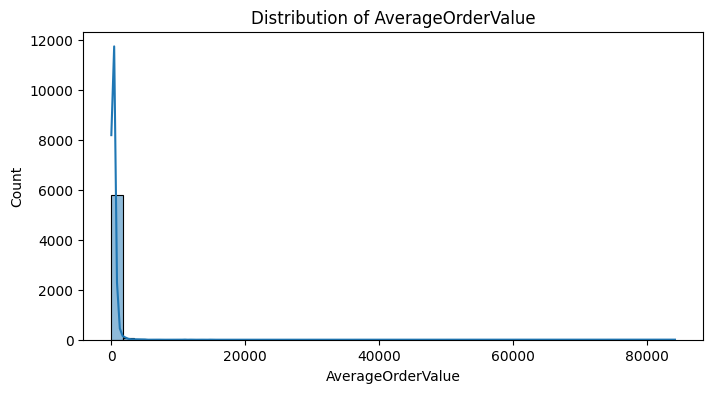

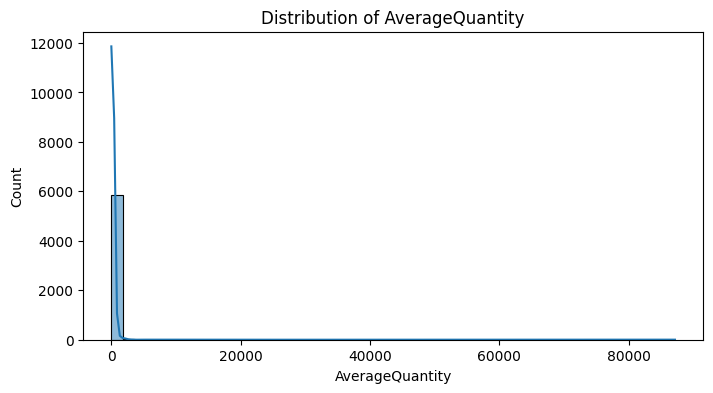

In [7]:
# Select numerical features for analysis
analysis_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "CustomerTenure",
    "AverageOrderValue",
    "AverageQuantity"
]

# Descriptive statistics
display(
    customer_features[analysis_features].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).T
)

# Skewness analysis
print("\nFeature Skewness:")
display(
    customer_features[analysis_features]
    .skew()
    .sort_values(ascending=False)
    .to_frame("Skewness")
)

# Distribution plots
for feature in analysis_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(
        customer_features[feature],
        bins=50,
        kde=True
    )
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.show()

**the customer data is heavily right-skewed.**

In [8]:
from sklearn.preprocessing import StandardScaler

# Select clustering features
clustering_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "CustomerTenure",
    "AverageOrderValue",
    "AverageQuantity"
]

# Create modelling dataset
X = customer_features[clustering_features].copy()

# Apply log1p transformation
X_log = np.log1p(X)

# Standardise features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

# Convert back to DataFrame for inspection
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=customer_features.index
)

print("Original feature shape:", X.shape)
print("Transformed feature shape:", X_scaled_df.shape)

print("\nScaled feature statistics:")
display(X_scaled_df.describe().round(3))

print("\nMissing values:", X_scaled_df.isnull().sum().sum())

Original feature shape: (5878, 6)
Transformed feature shape: (5878, 6)

Scaled feature statistics:


,Recency,Frequency,Monetary,CustomerTenure,AverageOrderValue,AverageQuantity
count,5878.000,5878.000,5878.000,5878.000,5878.000,5878.000
mean,-0.000,0.000,0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.412,-1.058,-3.929,-1.489,-5.764,-4.645
25%,-0.743,-1.058,-0.706,-1.489,-0.594,-0.510
50%,0.077,-0.202,-0.036,0.520,0.025,0.050
75%,0.955,0.655,0.651,0.832,0.562,0.603
max,1.380,5.485,4.660,0.969,7.776,6.892



Missing values: 0


### Elbow method and silhouette Score

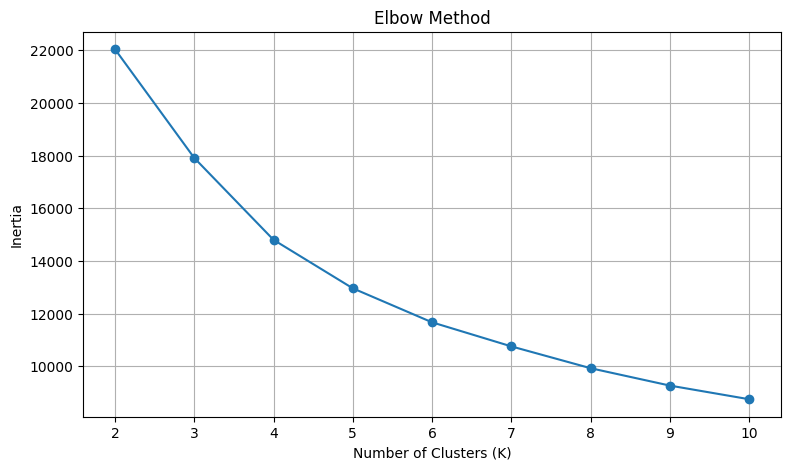

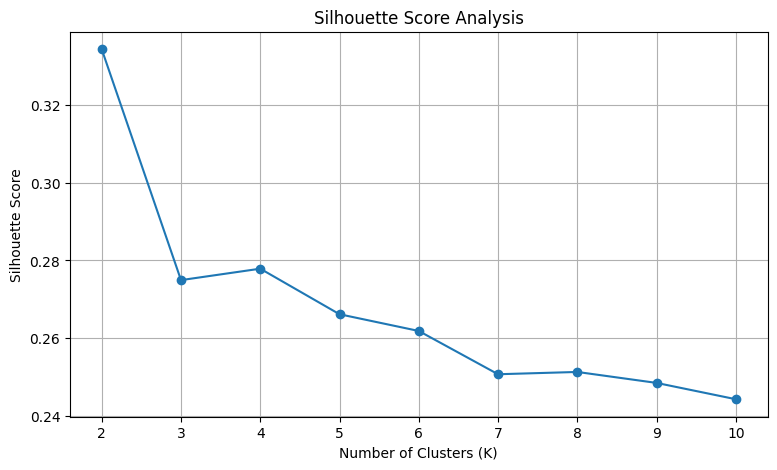

,K,Inertia,Silhouette Score
0,2,22040.4529,0.3344
1,3,17912.0508,0.2749
2,4,14801.8220,0.2779
3,5,12960.4685,0.2661
4,6,11668.6530,0.2618
5,7,10754.7123,0.2507
6,8,9925.7486,0.2513
7,9,9265.8054,0.2484
8,10,8747.4258,0.2442


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

# Elbow Method
plt.figure(figsize=(9, 5))
plt.plot(K_range, inertia_values, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

# Silhouette Score
plt.figure(figsize=(9, 5))
plt.plot(K_range, silhouette_values, marker='o')
plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

# Results table
cluster_evaluation = pd.DataFrame({
    "K": list(K_range),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(cluster_evaluation.round(4))

### We have two important observations:
- Elbow Method: The curve begins flattening around K=4–5.
- Silhouette Score: K=2 gives the highest score (0.3344), but K=4 improves slightly over K=3 (0.2779 vs 0.2749).

### Train k-means with 4 clusters

In [10]:
from sklearn.cluster import KMeans

# Train final K-Means model
kmeans_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

# Assign cluster labels
customer_features["Cluster"] = kmeans_model.fit_predict(X_scaled)

# Cluster distribution
print("Customer distribution across clusters:")
display(
    customer_features["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Customer Count")
)

# Cluster percentages
print("\nCluster percentages:")
display(
    (
        customer_features["Cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2).to_frame("Percentage")
)

print("\nModel inertia:", round(kmeans_model.inertia_, 2))
print(
    "Silhouette Score:",
    round(silhouette_score(X_scaled, customer_features["Cluster"]), 4)
)

Customer distribution across clusters:


,Customer Count
Cluster,
0,2366
1,1039
2,1524
3,949



Cluster percentages:


,Percentage
Cluster,
0,40.25
1,17.68
2,25.93
3,16.14



Model inertia: 14801.82
Silhouette Score: 0.2779


### Analyze Customer Segments

In [11]:
# Features for cluster profiling
profile_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "CustomerTenure",
    "AverageOrderValue",
    "AverageQuantity"
]

# Calculate mean values
cluster_profile = customer_features.groupby("Cluster")[
    profile_features
].mean().round(2)

# Calculate median values
cluster_median = customer_features.groupby("Cluster")[
    profile_features
].median().round(2)

print("CLUSTER PROFILE — MEAN VALUES")
display(cluster_profile)

print("\nCLUSTER PROFILE — MEDIAN VALUES")
display(cluster_median)

# Customer count per cluster
print("\nCUSTOMER COUNT")
display(
    customer_features.groupby("Cluster")
    .size()
    .to_frame("CustomerCount")
)

CLUSTER PROFILE — MEAN VALUES


,Recency,Frequency,Monetary,CustomerTenure,AverageOrderValue,AverageQuantity
Cluster,,,,,,
0,172.00,4.27,1051.78,322.94,267.74,155.02
1,336.58,1.15,638.26,4.26,534.88,409.62
2,45.60,15.99,9225.24,533.35,622.91,396.88
3,376.49,1.37,172.68,24.78,132.32,61.02



CLUSTER PROFILE — MEDIAN VALUES


,Recency,Frequency,Monetary,CustomerTenure,AverageOrderValue,AverageQuantity
Cluster,,,,,,
0,104.0,3.0,906.69,324.0,242.39,131.37
1,380.0,1.0,381.09,0.0,358.56,223.00
2,20.5,11.0,4297.54,596.0,412.93,250.10
3,401.0,1.0,144.20,0.0,120.84,55.00



CUSTOMER COUNT


,CustomerCount
Cluster,
0,2366
1,1039
2,1524
3,949


### Calculate segment revenue contribution

In [12]:
# Revenue contribution by cluster
cluster_revenue = customer_features.groupby("Cluster").agg(
    CustomerCount=("Customer ID", "count"),
    TotalRevenue=("Monetary", "sum"),
    AverageRevenue=("Monetary", "mean"),
    MedianRevenue=("Monetary", "median"),
    AverageFrequency=("Frequency", "mean"),
    AverageRecency=("Recency", "mean")
).reset_index()

# Calculate revenue contribution
total_revenue = cluster_revenue["TotalRevenue"].sum()

cluster_revenue["RevenueContribution"] = (
    cluster_revenue["TotalRevenue"] / total_revenue
) * 100

cluster_revenue["CustomerContribution"] = (
    cluster_revenue["CustomerCount"] /
    cluster_revenue["CustomerCount"].sum()
) * 100

# Sort by revenue
cluster_revenue = cluster_revenue.sort_values(
    "TotalRevenue",
    ascending=False
)

display(cluster_revenue.round(2))

,Cluster,CustomerCount,TotalRevenue,AverageRevenue,MedianRevenue,AverageFrequency,AverageRecency,RevenueContribution,CustomerContribution
2,2,1524,14059266.33,9225.24,4297.54,15.99,45.60,80.92,25.93
0,0,2366,2488514.07,1051.78,906.69,4.27,172.00,14.32,40.25
1,1,1039,663149.33,638.26,381.09,1.15,336.58,3.82,17.68
3,3,949,163874.54,172.68,144.20,1.37,376.49,0.94,16.14


**Cluster 2 contains only 25.93% of customers but contributes 80.92% of total historical revenue.**

### Visualise customer segments

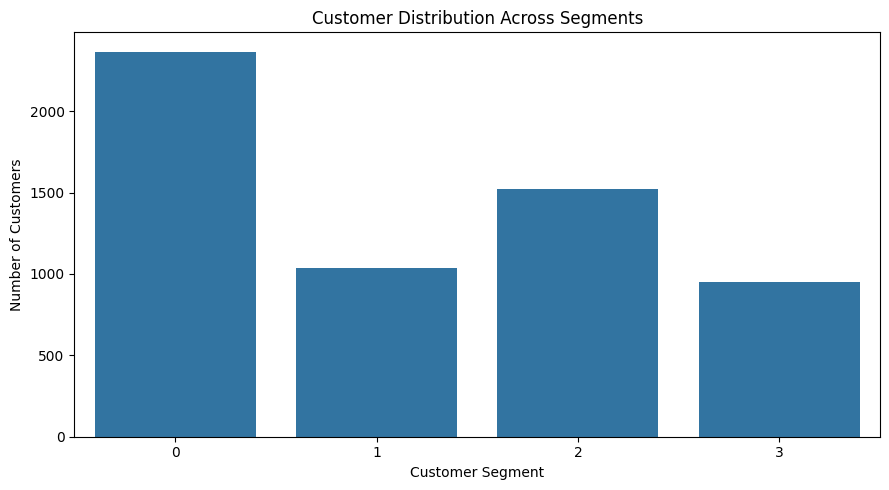

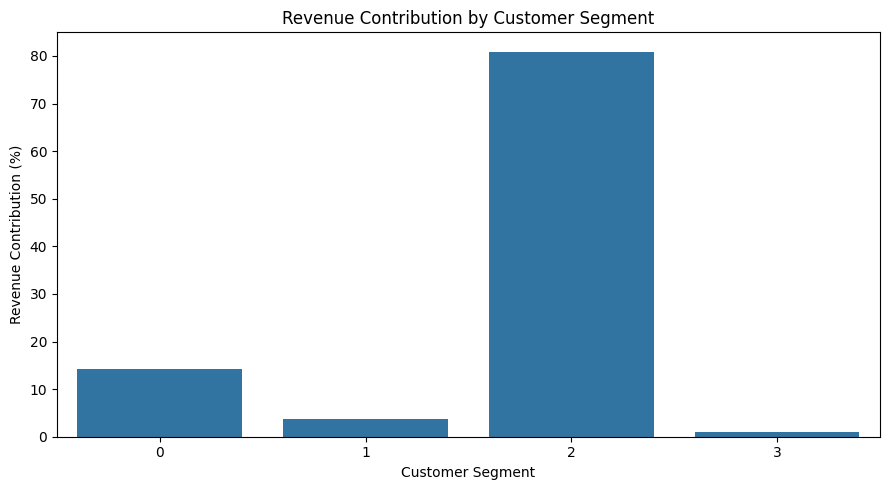

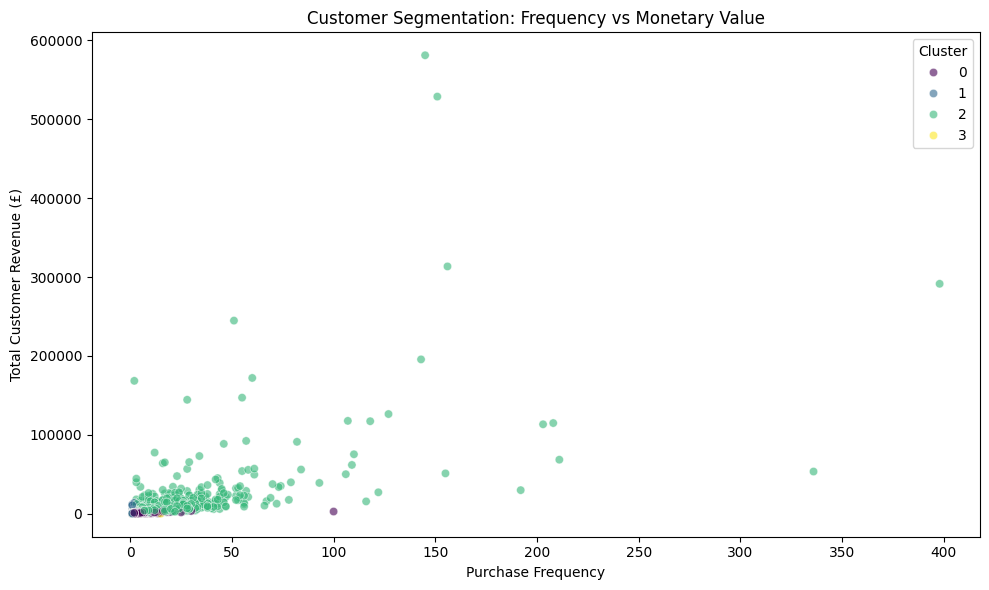

In [13]:
# 1. Customer distribution
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_revenue,
    x="Cluster",
    y="CustomerCount"
)

plt.title("Customer Distribution Across Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


# 2. Revenue contribution
plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_revenue,
    x="Cluster",
    y="RevenueContribution"
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")
plt.tight_layout()
plt.show()


# 3. Customer value vs engagement
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_features,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    alpha=0.6
)

plt.title("Customer Segmentation: Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Customer Revenue (£)")
plt.tight_layout()
plt.show()

### Finalize and save the segmentation field

In [14]:
import joblib

# Assign business-friendly segment names
segment_names = {
    0: "Regular Customers",
    1: "Dormant Higher-Value",
    2: "Champions",
    3: "Hibernating Customers"
}

customer_features["Segment"] = (
    customer_features["Cluster"].map(segment_names)
)

# Save customer segmentation dataset
customer_features.to_csv(
    os.path.join(DATA_PATH, "customer_segmentation.csv"),
    index=False
)

# Save trained model
joblib.dump(
    kmeans_model,
    os.path.join(MODEL_PATH, "kmeans_segmentation_model.pkl")
)

# Save scaler
joblib.dump(
    scaler,
    os.path.join(MODEL_PATH, "customer_segmentation_scaler.pkl")
)

# Save cluster profile
cluster_profile.to_csv(
    os.path.join(DATA_PATH, "cluster_profile.csv")
)

# Save revenue analysis
cluster_revenue.to_csv(
    os.path.join(DATA_PATH, "cluster_revenue_analysis.csv"),
    index=False
)

print("SEGMENTATION FILES SAVED SUCCESSFULLY")

print("\nSaved files:")
for folder in [DATA_PATH, MODEL_PATH]:
    print(f"\n{folder}")
    for file in os.listdir(folder):
        if "segment" in file.lower() or "cluster" in file.lower() or "kmeans" in file.lower():
            print(" -", file)

SEGMENTATION FILES SAVED SUCCESSFULLY

Saved files:

/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence/data
 - customer_segmentation.csv
 - cluster_profile.csv
 - cluster_revenue_analysis.csv

/content/drive/MyDrive/Customer-Lifetime-Value-Churn-Intelligence/models
 - kmeans_segmentation_model.pkl
 - customer_segmentation_scaler.pkl


# Customer Segmentation — Business Insights and Recommendations

## 1. Segmentation Overview

K-Means clustering was applied to 5,878 customers using six behavioural features:

- Recency
- Frequency
- Monetary
- Customer Tenure
- Average Order Value
- Average Quantity

Logarithmic transformation and StandardScaler were applied before clustering.

The Elbow Method and Silhouette Score were used to evaluate different cluster counts. Four clusters were selected for further business interpretation.

**Final Silhouette Score: 0.2779**

The score indicates moderate-to-weak cluster separation, suggesting some overlap between customer groups.

## 2. Identified Customer Segments

| Segment | Customers | Customer Share | Revenue Share |
|---|---:|---:|---:|
| Champions | 1,524 | 25.93% | 80.92% |
| Regular Customers | 2,366 | 40.25% | 14.32% |
| Dormant Higher-Value | 1,039 | 17.68% | 3.82% |
| Hibernating Customers | 949 | 16.14% | 0.94% |

## 3. Business Recommendations

### Champions
- Introduce VIP loyalty programmes.
- Provide exclusive offers and early access.
- Prioritise retention activities.

### Regular Customers
- Encourage repeat purchases.
- Recommend complementary products.
- Introduce loyalty incentives.

### Dormant Higher-Value
- Launch personalised win-back campaigns.
- Offer relevant product recommendations.
- Investigate reasons for inactivity.

### Hibernating Customers
- Use low-cost reactivation campaigns.
- Test targeted discounts.
- Avoid excessive retention spending on low-value customers.

## 4. Key Business Findings

- Champions represent approximately 26% of customers but generate approximately 81% of historical revenue.
- Regular Customers form the largest segment.
- Dormant Higher-Value customers offer a potential reactivation opportunity.
- Hibernating Customers contribute less than 1% of historical revenue.

## 5. Limitations

- K-Means requires a predefined number of clusters.
- The silhouette score indicates overlapping customer groups.
- Extreme spending behaviour can influence cluster formation.
- Segment labels are business interpretations, not actual customer classifications.
- Historical purchasing behaviour does not guarantee future purchasing behaviour.
- This segmentation is based on the Online Retail II dataset and may not generalise to other businesses.

## 6. Conclusion

The K-Means segmentation model identifies four customer groups with different purchasing behaviours and historical revenue contributions.

The findings can support customer prioritisation, targeted marketing, retention planning and resource allocation.

The model complements the project's churn prediction and CLV estimation components by providing an additional behavioural view of customers.